# Storages: Pumped Hydro and Seasonal Hydrogen Storage

The [basic tutorial](_2_basic_tutorial.ipynb) used one storage: batteries, which shift electricity by a few hours. This notebook adds two storages that work on very different time scales:

| Component | New parameters | What they do |
|---|---|---|
| Pumped hydro storage | `capacityFix` (on a storage) | fixes the capacity of storages that already exist |
| | `chargeRate` ≠ `dischargeRate` | different speeds for charging and discharging |
| Salt caverns (hydrogen) | `stateOfChargeMin` | a minimum filling level that must always stay in the storage |
| | slow `chargeRate` and `dischargeRate` | a large storage that can only be filled and emptied slowly |

We also look at how a storage can shift energy from one season to another, although the model only operates a few typical days.

## 1. The model of the basic tutorial, climate neutral in 2040

The function `buildBasicTutorialModel` in the file [basicTutorialModel.py](basicTutorialModel.py) next to this notebook builds exactly the model of the basic tutorial. Seasonal storage becomes important when hardly any fossil backup is left, so we lower the CO<sub>2</sub> limit for 2040 to 0. We also add the commodity `hydrogen` for the salt caverns. `readData` reads one of the CSV files in `examples/data/twoRegions`.

In [1]:
import warnings

import pandas as pd

import fine as fn
from basicTutorialModel import buildBasicTutorialModel, readData

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

esM = buildBasicTutorialModel(
    co2LimitPerPeriod={2020: 90, 2030: 45, 2040: 0},
    commodityUnits={"hydrogen": "GW_H2"},
)
existingCapacity = readData("existingCapacity.csv")
capacityPotential = readData("capacityPotential.csv")

## 2. Pumped hydro storage

A pumped hydro storage pumps water into an upper reservoir when electricity is cheap and lets it flow back through a turbine when electricity is needed. Germany has about 77 GWh of them, most of them in the north (in the low mountain ranges of the center of Germany, which belong to our north region):

In [2]:
existingCapacity.loc[["Pumped hydro storage"]]  # GWh

,north,south
technology,,
Pumped hydro storage,53.8,23.1


As for the run-of-river plants in the [Sources notebook](_3_sources.ipynb), **`capacityFix`** fixes the capacity of the existing plants, and we give no investment cost. The pumps and the turbines of a pumped hydro storage have different sizes, so **`chargeRate`** and **`dischargeRate`** differ: the storage can be filled in about 6 hours (0.16 of its capacity per hour) and emptied in about 8 hours (0.12 per hour). About 12 % of the energy is lost when charging and again when discharging.

In [3]:
esM.add(
    fn.Storage(
        esM=esM,
        name="Pumped hydro storage",
        commodity="electricity",
        hasCapacityVariable=True,
        capacityFix=existingCapacity.loc["Pumped hydro storage"],  # GWh
        chargeRate=0.16,
        dischargeRate=0.12,
        chargeEfficiency=0.88,
        dischargeEfficiency=0.88,
        opexPerCapacity=0.15,  # million Euro per GWh and year
    )
)

## 3. Hydrogen storage in salt caverns

Batteries and pumped hydro storage can shift electricity by hours. But there can be weeks with little wind and sun, and the energy for them has to be stored weeks or even months earlier. This needs a storage that is very large and cheap per GWh. Hydrogen can be stored in salt caverns: huge cavities in underground salt deposits, which exist in northern Germany only:

In [4]:
capacityPotential.loc[["Salt caverns (hydrogen)"]]  # GWh of hydrogen

,north,south
technology,,
Salt caverns (hydrogen),69396.2,0.0


To use them for electricity, the system needs electrolyzers that produce the hydrogen from electricity and power plants that turn it back into electricity. Both are conversions, as introduced in the [Conversions notebook](_5_conversions.ipynb):

In [5]:
esM.add(
    fn.Conversion(
        esM=esM,
        name="Electrolyzers",
        physicalUnit="GW_el",
        commodityConversionFactors={"electricity": -1, "hydrogen": 0.7},
        hasCapacityVariable=True,
        investPerCapacity={2020: 1500, 2030: 800, 2040: 500},  # million Euro per GW_el
        opexPerCapacity=30,
        interestRate=0.08,
        economicLifetime=20,
    )
)

esM.add(
    fn.Conversion(
        esM=esM,
        name="Hydrogen power plants",
        physicalUnit="GW_el",
        commodityConversionFactors={"electricity": 1, "hydrogen": -1 / 0.6},
        hasCapacityVariable=True,
        investPerCapacity=700,  # million Euro per GW_el
        opexPerCapacity=21,
        interestRate=0.08,
        economicLifetime=30,
    )
)

The salt caverns themselves are a storage of the commodity `hydrogen`. Their potential (`capacityMax`) is 0 in the south, so FINE only allows them in the north. Two parameters describe their special properties:

- **`chargeRate`** and **`dischargeRate`**: a cavern can only be filled or emptied slowly. A rate of 1/470 means that filling an empty cavern takes at least 470 hours, almost three weeks.
- **`stateOfChargeMin`**: the lowest allowed filling level, as a share of the capacity. A third of the hydrogen (the cushion gas) always has to stay in the cavern to keep the pressure up, so only two thirds of the capacity can be used.

Per GWh, a cavern is several hundred times cheaper than a battery.

In [6]:
esM.add(
    fn.Storage(
        esM=esM,
        name="Salt caverns (hydrogen)",
        commodity="hydrogen",
        hasCapacityVariable=True,
        capacityMax=capacityPotential.loc["Salt caverns (hydrogen)"],  # GWh_H2
        chargeRate=1 / 470,
        dischargeRate=1 / 470,
        stateOfChargeMin=0.33,
        investPerCapacity=0.3,  # million Euro per GWh_H2
        opexPerCapacity=0.01,
        interestRate=0.08,
        economicLifetime=30,
    )
)

## 4. Optimize

The model operates only 8 typical days per year. How can a storage then shift energy from summer to winter? FINE links the typical days in the order in which they occur in the original year. The filling level of a storage is carried over from one day to the next, so it can rise over many days and fall over many others. This is the default. For storages that only shift energy within a day, `isPeriodicalStorage=True` forces the filling level to be the same at the start and the end of each typical day, which makes the problem a bit smaller.

In [7]:
esM.aggregateTemporally(numberOfTypicalPeriods=8)

In [8]:
esM.optimize(
    timeSeriesAggregation=True,
    solver=fn.utils.ImplementedSolvers.STANDARD_SOLVER.value,
)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (72 outputs left out)

Solved with barrier


    5077    5.7701065e+05   0.000000e+00   0.000000e+00      2s


Solved in 5077 iterations and 2.28 seconds (2.40 work units)


Optimal objective  5.770106514e+05


## 5. Results

### Storage capacities

The capacities of all storages, both regions added up, in GWh:

In [9]:
storageCapacity = pd.DataFrame(
    {
        year: esM.getOptimizationSummary("StorageModel", outputLevel=1, ip=year)
        .xs("capacity", level="Property")
        .droplevel("Unit")
        .sum(axis=1)
        for year in esM.investmentPeriodNames
    }
)
storageCapacity.columns.name = "Capacity [GWh]"
storageCapacity.astype(float).round(0)

Capacity [GWh],2020,2030,2040
Component,,,
Batteries,0.0,123.0,163.0
Pumped hydro storage,77.0,77.0,77.0
Salt caverns (hydrogen),0.0,1169.0,42992.0


The pumped hydro storage keeps its fixed capacity of 77 GWh. In 2040, when no CO<sub>2</sub> may be emitted at all, the model builds about 43 TWh of salt caverns in the north, more than 250 times the capacity of the batteries (about 160 GWh). To fill and empty the caverns, it needs large electrolyzers and hydrogen power plants:

In [10]:
esM.getOptimizationSummary("ConversionModel", outputLevel=2, ip=2040).xs(
    "capacity", level="Property"
).astype(float).round(1)

,,north,south
Component,Unit,,
Electrolyzers,[GW_el],111.7,0.0
Gas power plants,[GW_el],29.2,28.6
Hydrogen power plants,[GW_el],54.9,0.0


All of them are in the north, next to the caverns, since hydrogen cannot be transported between the regions in this model. The gas power plants are still there, but they do not run in 2040.

Although no CO<sub>2</sub> may be emitted in 2040, the total cost (`esM.objectiveValue`, about 577 billion Euro) is lower than in the basic tutorial with 20 million tonnes (about 596 billion Euro): the hydrogen storage replaces a large part of the batteries and of the wind turbines in the less windy south.

### Filling levels over the year

`fn.plotOperation` plots the hourly operation of a component in one region as a line. With `variableName="stateOfChargeOperationVariablesOptimum"` it shows the filling level of a storage. Here are the salt caverns and the batteries in the north in 2040, both over the whole year:

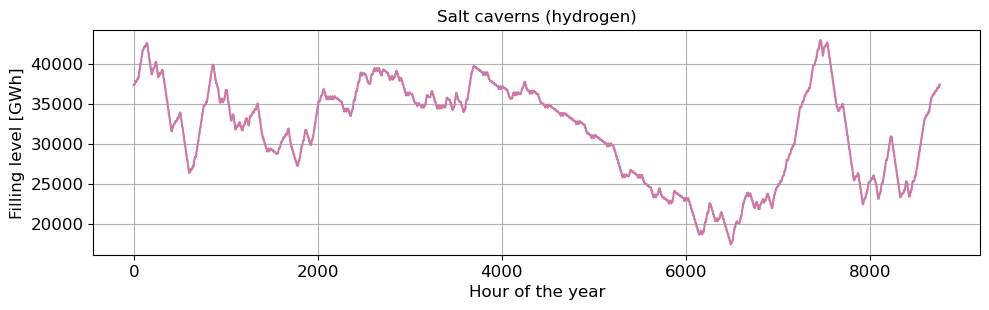

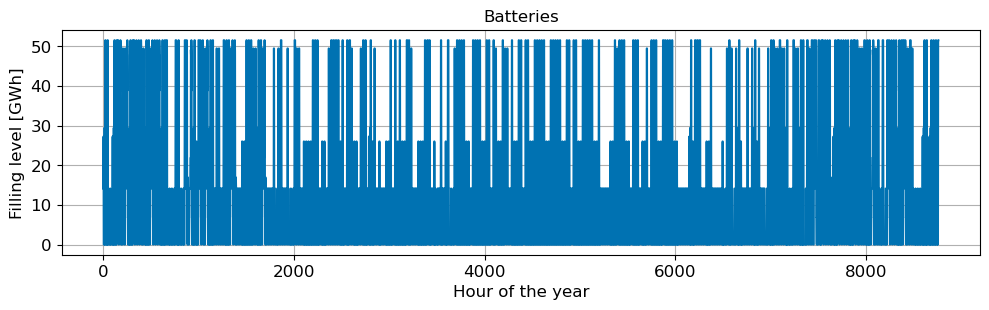

In [11]:
for storage, color in {
    "Salt caverns (hydrogen)": "#CC79A7",
    "Batteries": "#0072B2",
}.items():
    fig, ax = fn.plotOperation(
        esM,
        storage,
        "north",
        variableName="stateOfChargeOperationVariablesOptimum",
        ip=2040,
        xlabel="Hour of the year",
        ylabel="Filling level [GWh]",
        figsize=(10, 3),
        color=color,
    )
    ax.set_title(storage)

The filling level of the salt caverns changes slowly, over weeks and months. It is high in spring and early summer, falls in the calm late summer, when the wind turbines produce little and PV cannot cover the nights, reaches its lowest level in September and rises again in the windy autumn. At the end of the year, it is back at its level at the start, so that the year could be repeated. The batteries, in contrast, are filled and emptied within a day, over and over again.

## Things to try

- Remove the salt caverns. How large do the batteries become in 2040?
- Set `stateOfChargeMin` of the salt caverns to 0. How much smaller can the caverns be?
- Set the CO<sub>2</sub> limit for 2040 back to 20 million tonnes, as in the basic tutorial. Is the seasonal storage still worth it?

The next notebook, [Transmissions](_7_transmissions.ipynb), adds the existing grid and HVDC cables.